Date :- 30/07/2026
# Assignment 3 :- Introduction to Dataset
1. Dataset Upload
2. Numpy & Pandas
3. Data Preprocessing

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
# NumPy
arr=np.array([10,20,30,40,50])
print(arr)
print(arr.mean(),arr.sum(),arr.max(),arr.min())
print(arr.shape)

[10 20 30 40 50]
30.0 150 50 10
(5,)


In [ ]:
matrix=np.array([[1,2,3],[4,5,6]])
print(matrix)
print(matrix.shape)

[[1 2 3]
 [4 5 6]]
(2, 3)


In [ ]:

# 1. Implement a numpy on two 3d array and perform arithematic operations like addition,suntraction,multiplication and division
arr1=np.array([[[1,2],[3,4]],[[5,6],[7,8]]])
arr2=np.array([[[10,20],[30,40]],[[50,60],[70,80]]])
print("Array 1 : \n",arr1)
print("Array 2 : \n",arr2)
print("Addition : \n",arr1+arr2)
print("Subtraction : \n",arr1-arr2)
print("Multiplication : \n",arr1*arr2)
print("Division : \n",arr1/arr2)

Array 1 : 
 [[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]
Array 2 : 
 [[[10 20]
  [30 40]]

 [[50 60]
  [70 80]]]
Addition : 
 [[[11 22]
  [33 44]]

 [[55 66]
  [77 88]]]
Subtraction : 
 [[[ -9 -18]
  [-27 -36]]

 [[-45 -54]
  [-63 -72]]]
Multiplication : 
 [[[ 10  40]
  [ 90 160]]

 [[250 360]
  [490 640]]]
Division : 
 [[[0.1 0.1]
  [0.1 0.1]]

 [[0.1 0.1]
  [0.1 0.1]]]


In [ ]:
# 2. Implement the average , maximum value, minimum value, and standred deviation on array by using numpy
arr=np.array([10,20,30,40,50])
print(arr.mean(),arr.max(),arr.min(),arr.std())

30.0 50 10 14.142135623730951


In [ ]:
# 3. Write the code to load the iris dataset using pandas and perform the following operations
#1. Display first 5 records
#2. Display last 5 records
#3. Show the dataset information
#4. Provide statistical summary

import seaborn as sns
data=sns.load_dataset("iris")
print(data.head())
print(data.tail())
print(data.info())
print(data.describe())


   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
     sepal_length  sepal_width  petal_length  petal_width    species
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_l

In [ ]:
import seaborn as sns
data=sns.load_dataset("titanic")

In [ ]:
print(data)

     survived  pclass     sex   age  sibsp  parch     fare embarked   class  \
0           0       3    male  22.0      1      0   7.2500        S   Third   
1           1       1  female  38.0      1      0  71.2833        C   First   
2           1       3  female  26.0      0      0   7.9250        S   Third   
3           1       1  female  35.0      1      0  53.1000        S   First   
4           0       3    male  35.0      0      0   8.0500        S   Third   
..        ...     ...     ...   ...    ...    ...      ...      ...     ...   
886         0       2    male  27.0      0      0  13.0000        S  Second   
887         1       1  female  19.0      0      0  30.0000        S   First   
888         0       3  female   NaN      1      2  23.4500        S   Third   
889         1       1    male  26.0      0      0  30.0000        C   First   
890         0       3    male  32.0      0      0   7.7500        Q   Third   

       who  adult_male deck  embark_town alive  alo

In [ ]:
df=pd.read_csv("Titanic-Dataset.csv")

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
print(numeric_cols)
outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_summary.append({
        "Column": col,
        "Outliers": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')


,Column,Outliers
0,PassengerId,0
1,Survived,0
2,Pclass,0
3,Age,11
4,SibSp,46
5,Parch,213
6,Fare,116


In [ ]:

Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["Fare"] = df["Fare"].clip(lower=lower, upper=upper)

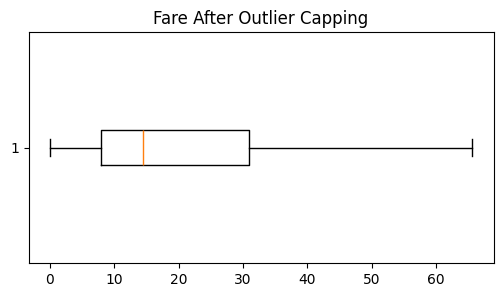

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,3))
plt.boxplot(df["Fare"], vert=False)
plt.title("Fare After Outlier Capping")
plt.show()

In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,24.046813
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,20.481625
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,65.634400
